# Levenshtein distance: consistent vs inconsistent

Run `make_conditions.py` first, it writes the CSVs this notebook reads.
Put this notebook in the same folder as `make_conditions.py` (so `output/` is one level up).

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# In a notebook there is no __file__, so we start from the folder the notebook runs in.
OUT = Path.cwd() / "output"
print(OUT, "exists:", OUT.exists())

c:\Users\gmoha\OneDrive\文档\GitHub\PhD-HUM-AI-N-ACCENT\text_analysis\output exists: True


## 1. Load the data

`sections.csv` has one row per section per version (`consistent_R1`, `consistent_R2`, `consistent_R3`, `inconsistent`).

- `pw`   = per-word Levenshtein / phonemes of the word, mean over words in a sentence, then over sentences (in %)
- `pw_w` = the same with the weighted costs (`SUB_WEIGHTS`)

In [4]:
sections = pd.read_csv(OUT / "sections.csv")
words = pd.read_csv(OUT / "words.csv")

print(sections.shape, words.shape)
sections[["section", "version", "condition", "rule", "changes", "pw", "pw_w"]]

(36, 22) (27592, 16)


,section,version,condition,rule,changes,pw,pw_w
0,story1_p1,consistent_R1,consistent,R1,600,16.161,17.076
1,story1_p1,consistent_R2,consistent,R2,702,21.314,26.031
2,story1_p1,consistent_R3,consistent,R3,639,14.136,12.499
3,story1_p1,inconsistent,inconsistent,NaN,647,18.071,19.344
4,story1_p2,consistent_R1,consistent,R1,580,17.040,19.307
5,story1_p2,consistent_R2,consistent,R2,614,19.845,24.196
6,story1_p2,consistent_R3,consistent,R3,637,15.502,13.281
7,story1_p2,inconsistent,inconsistent,NaN,610,17.450,18.700
8,story1_p3,consistent_R1,consistent,R1,594,16.257,17.225
9,story1_p3,consistent_R2,consistent,R2,664,20.528,24.981


In [5]:
words

,section,story,part,version,condition,rule,sentence,word,native,manipulated,phonemes,changes,lev,lev_w,d,d_w
0,story1_p1,1,1,consistent_R1,consistent,R1,0,0,sˈaɾa,sˈaɾa,4,0,0.0,0.0,0.0000,0.0000
1,story1_p1,1,1,consistent_R1,consistent,R1,0,1,lavorˈava,lavorˈava,8,0,0.0,0.0,0.0000,0.0000
2,story1_p1,1,1,consistent_R1,consistent,R1,0,2,kˌome,xˌome,4,1,1.0,2.0,0.2500,0.5000
3,story1_p1,1,1,consistent_R1,consistent,R1,0,3,botˈanika,botʲˈanyxa,8,3,3.0,3.5,0.3750,0.4375
4,story1_p1,1,1,consistent_R1,consistent,R1,0,4,allʊniversitˈa,allʊnyversytʲˈa,13,3,3.0,2.5,0.2308,0.1923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27587,story3_p3,3,3,inconsistent,inconsistent,NaN,35,27,stˈeSo,stʲˈeSo,5,1,1.0,0.5,0.2000,0.1000
27588,story3_p3,3,3,inconsistent,inconsistent,NaN,35,28,ˈɔrdine,ˈɔrdinø,6,1,1.0,1.0,0.1667,0.1667
27589,story3_p3,3,3,inconsistent,inconsistent,NaN,35,29,ʊzˈato,ʊzˈaθo,5,1,1.0,2.0,0.2000,0.4000
27590,story3_p3,3,3,inconsistent,inconsistent,NaN,35,30,ˌalla,ˌalla,4,0,0.0,0.0,0.0000,0.0000


## 2. One value per section per condition

Every section exists with all 3 consistent rules (they are counterbalanced across participants),
so we average R1-R3 to get the expected consistent distance of that section.

In [6]:
per_sec = (sections
           .groupby(["section", "story", "part", "condition"], as_index=False)[["pw", "pw_w"]]
           .mean())
per_sec

,section,story,part,condition,pw,pw_w
0,story1_p1,1,1,consistent,17.203667,18.535333
1,story1_p1,1,1,inconsistent,18.071000,19.344000
2,story1_p2,1,2,consistent,17.462333,18.928000
3,story1_p2,1,2,inconsistent,17.450000,18.700000
4,story1_p3,1,3,consistent,17.148000,18.419667
5,story1_p3,1,3,inconsistent,18.842000,20.019000
6,story2_p1,2,1,consistent,17.249667,18.560667
7,story2_p1,2,1,inconsistent,17.699000,18.909000
8,story2_p2,2,2,consistent,17.773667,19.127000
9,story2_p2,2,2,inconsistent,18.002000,19.248000


In [ ]:
# mean, sd and number of sections per condition
per_sec.groupby("condition")[["pw", "pw_w"]].agg(["mean", "std", "count"]).round(2)

## 3. Plot: average distance per condition

Bars = mean over sections (error bar = SD). Grey lines connect the two conditions of the same section.

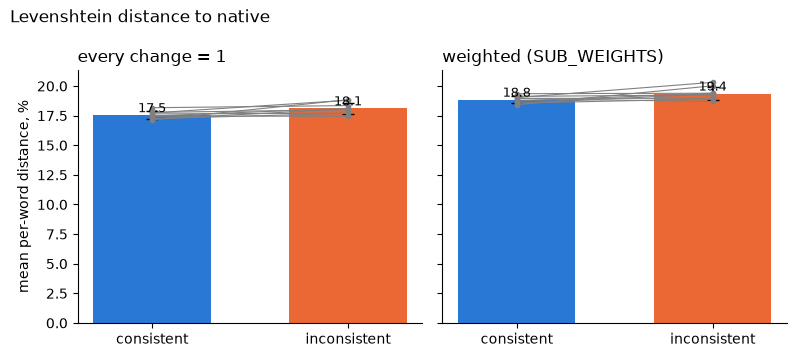

In [7]:
conds = ["consistent", "inconsistent"]
colors = {"consistent": "#2a78d6", "inconsistent": "#eb6834"}
metrics = [("pw", "every change = 1"), ("pw_w", "weighted (SUB_WEIGHTS)")]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
for ax, (m, title) in zip(axes, metrics):
    wide = per_sec.pivot(index="section", columns="condition", values=m)[conds]
    ax.bar([0, 1], wide.mean(), yerr=wide.std(), capsize=4, width=0.6,
           color=[colors[c] for c in conds])
    for _, row in wide.iterrows():                     # one line per section
        ax.plot([0, 1], row.values, color="grey", lw=0.8, marker="o", ms=3)
    for i, v in enumerate(wide.mean()):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks([0, 1], conds)
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("mean per-word distance, %")
fig.suptitle("Levenshtein distance to native", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 4. Per section, and the difference

condition,consistent,inconsistent,inc - cons
section,,,
story1_p1,17.20,18.07,0.87
story1_p2,17.46,17.45,-0.01
story1_p3,17.15,18.84,1.69
story2_p1,17.25,17.70,0.45
story2_p2,17.77,18.00,0.23
story2_p3,17.47,18.12,0.65
story3_p1,17.65,17.70,0.06
story3_p2,17.73,18.80,1.07
story3_p3,18.17,18.35,0.18


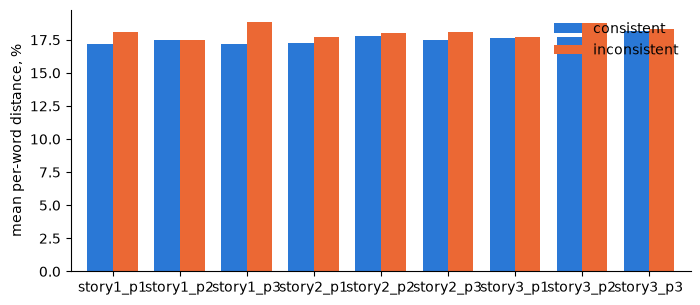

In [8]:
wide = per_sec.pivot(index="section", columns="condition", values="pw")[conds]
wide["inc - cons"] = wide["inconsistent"] - wide["consistent"]
display(wide.round(2))

ax = wide[conds].plot.bar(figsize=(8, 3.4), rot=0, width=0.75,
                          color=[colors[c] for c in conds])
ax.set_ylabel("mean per-word distance, %")
ax.set_xlabel("")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Check from the word level

`words.csv` has every word: `d` = distance / phonemes of the word (0-1).
Pooling all words weights every word equally (`pw` averages within each sentence first),
so these numbers are close to, but not the same as, the ones above.

In [9]:
words.groupby("condition")[["d", "d_w"]].mean().mul(100).round(2)

,d,d_w
condition,,
consistent,17.58,18.89
inconsistent,18.19,19.43


In [10]:
# only the words that were actually changed
changed = words[words["lev"] > 0]
changed.groupby("condition")[["d", "d_w", "changes"]].mean().round(3)

,d,d_w,changes
condition,,,
consistent,0.324,0.348,1.533
inconsistent,0.333,0.356,1.521


In [14]:
from scipy import stats
from statsmodels.stats.weightstats import ttost_paired

# sentence-level pw: mean d over the words of each sentence (in %)
# dropna=False because `rule` is empty (NaN) for the inconsistent rows,
# and groupby would silently drop them otherwise
sent = (words.groupby(["section", "sentence", "condition", "rule"], dropna=False)["d"].mean()
             .groupby(["section", "sentence", "condition"]).mean()   # average R1-R3
             .unstack("condition") * 100)

cons, inc = sent["consistent"], sent["inconsistent"]
diff = inc - cons
print(diff.describe())

# 1) difference test
print(stats.ttest_rel(inc, cons))
print(stats.wilcoxon(inc, cons))          # non-parametric version

# 2) equivalence test: is the difference inside ±1 point?
margin = 1.0
p, lower, upper = ttost_paired(inc.values, cons.values, -margin, margin)
print(f"TOST p = {p:.4f}  (p < .05 -> equivalent within ±{margin})")

# effect size (paired Cohen's d)
print("d_z =", diff.mean() / diff.std())

count    336.000000
mean       0.588702
std        3.880980
min       -9.187255
25%       -1.987019
50%        0.488845
75%        3.111029
max       15.097407
dtype: float64
TtestResult(statistic=np.float64(2.7805075488220625), pvalue=np.float64(0.005734225260757293), df=np.int64(335))
WilcoxonResult(statistic=np.float64(23951.0), pvalue=np.float64(0.014480196038440252))
TOST p = 0.0265  (p < .05 -> equivalent within ±1.0)
d_z = 0.15168912277230026
